In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
data = np.load("spectrum_sensing_dataset.npz")

X_data = data["X"]
y_data = data["y"]
snr_data = data["snr"]

print("Dataset loaded successfully!")
print("X shape:", X_data.shape)
print("y shape:", y_data.shape)
print("SNR shape:", snr_data.shape)

Dataset loaded successfully!
X shape: (14000, 256)
y shape: (14000,)
SNR shape: (14000,)


In [2]:
def extract_energy_features(signal):

    # Average signal energy
    energy = np.mean(np.abs(signal)**2)

    # Logarithmic energy
    log_energy = np.log10(energy + 1e-12)

    # Root mean square amplitude
    rms = np.sqrt(energy)

    return [energy, log_energy, rms]

In [3]:
# Select one H0 and one H1 observation
h0_sample = X_data[np.where(y_data == 0)[0][0]]
h1_sample = X_data[np.where(y_data == 1)[0][0]]

# Extract features
h0_features = extract_energy_features(h0_sample)
h1_features = extract_energy_features(h1_sample)

print("H0 Energy Features:")
print("Average Energy:", h0_features[0])
print("Log Energy:", h0_features[1])
print("RMS Amplitude:", h0_features[2])

print("\nH1 Energy Features:")
print("Average Energy:", h1_features[0])
print("Log Energy:", h1_features[1])
print("RMS Amplitude:", h1_features[2])

H0 Energy Features:
Average Energy: 97.95433884916125
Log Energy: 1.9910236776611823
RMS Amplitude: 9.897188431527473

H1 Energy Features:
Average Energy: 99.39579143345387
Log Energy: 1.9973679961083624
RMS Amplitude: 9.969743799790136


In [4]:
energy_features = []

for signal in X_data:

    features = extract_energy_features(signal)

    energy_features.append(features)

energy_features = np.array(energy_features)

print("Energy feature extraction completed!")
print("Energy feature matrix shape:", energy_features.shape)

Energy feature extraction completed!
Energy feature matrix shape: (14000, 3)


In [5]:
energy_df = pd.DataFrame(
    energy_features,
    columns=[
        "Average_Energy",
        "Log_Energy",
        "RMS_Amplitude"
    ]
)

energy_df["Label"] = y_data
energy_df["SNR"] = snr_data

energy_df.head()

,Average_Energy,Log_Energy,RMS_Amplitude,Label,SNR
0,97.954339,1.991024,9.897188,0,-20
1,101.710309,2.007365,10.085153,0,-20
2,93.942971,1.972864,9.692418,0,-20
3,105.268476,2.022298,10.260043,0,-20
4,105.593912,2.023639,10.275890,0,-20


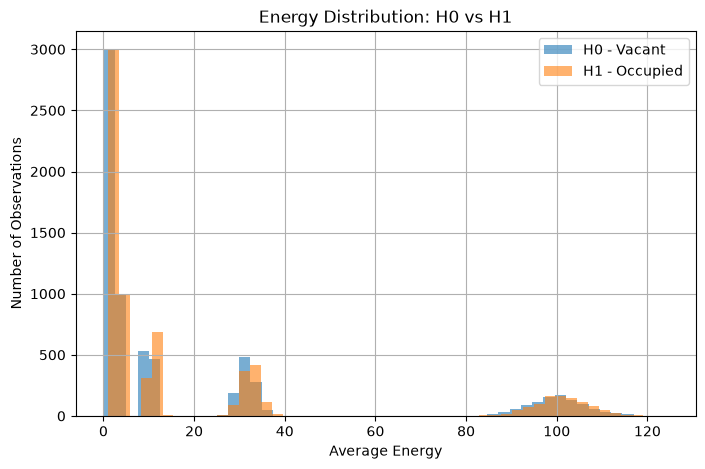

In [6]:
plt.figure(figsize=(8, 5))

plt.hist(
    energy_df[energy_df["Label"] == 0]["Average_Energy"],
    bins=50,
    alpha=0.6,
    label="H0 - Vacant"
)

plt.hist(
    energy_df[energy_df["Label"] == 1]["Average_Energy"],
    bins=50,
    alpha=0.6,
    label="H1 - Occupied"
)

plt.xlabel("Average Energy")
plt.ylabel("Number of Observations")
plt.title("Energy Distribution: H0 vs H1")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
from scipy.stats import skew, kurtosis

print("Statistical functions imported successfully!")

Statistical functions imported successfully!


In [8]:
def extract_statistical_features(signal):

    real_part = signal.real
    imag_part = signal.imag

    magnitude = np.abs(signal)

    features = [
        np.mean(real_part),
        np.mean(imag_part),
        np.std(real_part),
        np.std(imag_part),
        skew(magnitude),
        kurtosis(magnitude)
    ]

    return features

In [9]:
test_features = extract_statistical_features(X_data[0])

feature_names = [
    "Mean_I",
    "Mean_Q",
    "Std_I",
    "Std_Q",
    "Magnitude_Skewness",
    "Magnitude_Kurtosis"
]

for name, value in zip(feature_names, test_features):
    print(f"{name}: {value:.5f}")

Mean_I: -0.04708
Mean_Q: 0.24492
Std_I: 6.76209
Std_Q: 7.22262
Magnitude_Skewness: 0.57072
Magnitude_Kurtosis: 0.08747


In [10]:
statistical_features = []

for signal in X_data:

    features = extract_statistical_features(signal)

    statistical_features.append(features)

statistical_features = np.array(statistical_features)

print("Statistical feature extraction completed!")
print("Statistical feature matrix shape:",
      statistical_features.shape)

Statistical feature extraction completed!
Statistical feature matrix shape: (14000, 6)


In [11]:
statistical_df = pd.DataFrame(
    statistical_features,
    columns=[
        "Mean_I",
        "Mean_Q",
        "Std_I",
        "Std_Q",
        "Magnitude_Skewness",
        "Magnitude_Kurtosis"
    ]
)

statistical_df["Label"] = y_data
statistical_df["SNR"] = snr_data

statistical_df.head()

,Mean_I,Mean_Q,Std_I,Std_Q,Magnitude_Skewness,Magnitude_Kurtosis,Label,SNR
0,-0.047076,0.244923,6.762090,7.222622,0.570716,0.087465,0,-20
1,-0.522973,-0.369562,7.102171,7.131578,0.568835,-0.058091,0,-20
2,-0.040403,0.021355,7.006023,6.697501,0.595887,0.527430,0,-20
3,0.234439,-0.555271,7.420101,7.060261,0.682341,0.630436,0,-20
4,0.364030,-0.166135,7.246678,7.274576,0.529644,-0.240837,0,-20


In [12]:
def extract_frequency_features(signal):

    # Calculate FFT
    spectrum = np.fft.fft(signal)

    # Calculate power spectrum
    power_spectrum = np.abs(spectrum)**2

    # Normalise power spectrum
    total_power = np.sum(power_spectrum) + 1e-12
    normalized_power = power_spectrum / total_power

    # Frequency bins
    frequencies = np.fft.fftfreq(len(signal))

    # Use absolute frequencies for spectral statistics
    abs_frequencies = np.abs(frequencies)

    # Spectral centroid
    centroid = np.sum(
        abs_frequencies * normalized_power
    )

    # Spectral bandwidth
    bandwidth = np.sqrt(
        np.sum(
            ((abs_frequencies - centroid)**2)
            * normalized_power
        )
    )

    # Spectral entropy
    entropy = -np.sum(
        normalized_power *
        np.log2(normalized_power + 1e-12)
    )

    # Peak spectral power
    peak_power = np.max(normalized_power)

    return [
        centroid,
        bandwidth,
        entropy,
        peak_power
    ]

In [13]:
frequency_features = extract_frequency_features(X_data[0])

frequency_names = [
    "Spectral_Centroid",
    "Spectral_Bandwidth",
    "Spectral_Entropy",
    "Peak_Spectral_Power"
]

for name, value in zip(
    frequency_names,
    frequency_features
):
    print(f"{name}: {value:.6f}")

Spectral_Centroid: 0.244454
Spectral_Bandwidth: 0.143729
Spectral_Entropy: 7.360845
Peak_Spectral_Power: 0.027133


In [14]:
frequency_features_all = []

for signal in X_data:

    features = extract_frequency_features(signal)

    frequency_features_all.append(features)

frequency_features_all = np.array(
    frequency_features_all
)

print("Frequency feature extraction completed!")

print(
    "Frequency feature matrix shape:",
    frequency_features_all.shape
)

Frequency feature extraction completed!
Frequency feature matrix shape: (14000, 4)


In [15]:
frequency_df = pd.DataFrame(
    frequency_features_all,
    columns=[
        "Spectral_Centroid",
        "Spectral_Bandwidth",
        "Spectral_Entropy",
        "Peak_Spectral_Power"
    ]
)

frequency_df["Label"] = y_data
frequency_df["SNR"] = snr_data

frequency_df.head()

,Spectral_Centroid,Spectral_Bandwidth,Spectral_Entropy,Peak_Spectral_Power,Label,SNR
0,0.244454,0.143729,7.360845,0.027133,0,-20
1,0.264575,0.149080,7.376044,0.024418,0,-20
2,0.260100,0.146564,7.416075,0.025970,0,-20
3,0.252932,0.143393,7.489426,0.021863,0,-20
4,0.251956,0.143925,7.386451,0.028302,0,-20


In [16]:
# Combine all extracted features
X_features = np.concatenate(
    [
        energy_features,
        statistical_features,
        frequency_features_all
    ],
    axis=1
)

print("Combined feature matrix shape:", X_features.shape)

Combined feature matrix shape: (14000, 13)


In [17]:
feature_columns = [
    "Average_Energy",
    "Log_Energy",
    "RMS_Amplitude",
    "Mean_I",
    "Mean_Q",
    "Std_I",
    "Std_Q",
    "Magnitude_Skewness",
    "Magnitude_Kurtosis",
    "Spectral_Centroid",
    "Spectral_Bandwidth",
    "Spectral_Entropy",
    "Peak_Spectral_Power"
]

final_df = pd.DataFrame(
    X_features,
    columns=feature_columns
)

final_df["Label"] = y_data
final_df["SNR"] = snr_data

final_df.head()

,Average_Energy,Log_Energy,RMS_Amplitude,Mean_I,Mean_Q,Std_I,Std_Q,Magnitude_Skewness,Magnitude_Kurtosis,Spectral_Centroid,Spectral_Bandwidth,Spectral_Entropy,Peak_Spectral_Power,Label,SNR
0,97.954339,1.991024,9.897188,-0.047076,0.244923,6.762090,7.222622,0.570716,0.087465,0.244454,0.143729,7.360845,0.027133,0,-20
1,101.710309,2.007365,10.085153,-0.522973,-0.369562,7.102171,7.131578,0.568835,-0.058091,0.264575,0.149080,7.376044,0.024418,0,-20
2,93.942971,1.972864,9.692418,-0.040403,0.021355,7.006023,6.697501,0.595887,0.527430,0.260100,0.146564,7.416075,0.025970,0,-20
3,105.268476,2.022298,10.260043,0.234439,-0.555271,7.420101,7.060261,0.682341,0.630436,0.252932,0.143393,7.489426,0.021863,0,-20
4,105.593912,2.023639,10.275890,0.364030,-0.166135,7.246678,7.274576,0.529644,-0.240837,0.251956,0.143925,7.386451,0.028302,0,-20


In [18]:
print("Total observations:", len(final_df))
print("Total features:", len(feature_columns))

print("\nMissing values:")
print(final_df.isnull().sum())

print("\nClass distribution:")
print(final_df["Label"].value_counts())

print("\nFeature summary:")
print(final_df[feature_columns].describe())

Total observations: 14000
Total features: 13

Missing values:
Average_Energy         0
Log_Energy             0
RMS_Amplitude          0
Mean_I                 0
Mean_Q                 0
Std_I                  0
Std_Q                  0
Magnitude_Skewness     0
Magnitude_Kurtosis     0
Spectral_Centroid      0
Spectral_Bandwidth     0
Spectral_Entropy       0
Peak_Spectral_Power    0
Label                  0
SNR                    0
dtype: int64

Class distribution:
Label
0    7000
1    7000
Name: count, dtype: int64

Feature summary:
       Average_Energy    Log_Energy  RMS_Amplitude        Mean_I  \
count    14000.000000  14000.000000   14000.000000  14000.000000   
mean        21.403188      0.652076       3.368168      0.002383   
std         34.087782      0.873220       3.171648      0.202646   
min          0.080338     -1.095081       0.283439     -1.680406   
25%          1.103423      0.042742       1.050439     -0.053189   
50%          3.632317      0.560183       1.905863 

In [19]:
# Save combined feature dataset
final_df.to_csv(
    "spectrum_sensing_features.csv",
    index=False
)

np.savez_compressed(
    "spectrum_sensing_features.npz",
    X=X_features,
    y=y_data,
    snr=snr_data,
    feature_names=np.array(feature_columns)
)

print("Feature datasets saved successfully!")

Feature datasets saved successfully!


In [20]:
print("Infinite values:",
      np.isinf(X_features).sum())

print("CSV saved:",
      __import__("os").path.exists(
          "spectrum_sensing_features.csv"
      ))

print("NPZ saved:",
      __import__("os").path.exists(
          "spectrum_sensing_features.npz"
      ))

Infinite values: 0
CSV saved: True
NPZ saved: True
